In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../'))
sys.path.append(base_path)


import numpy as np
import tensorflow as tf

from data_loader_complete import DataLoader
import project_images_loader as pil
import utils.functions as fc

import discriminator as Discriminator
import generator as Generator
# import feature_extractor as feature_extractor

tf.keras.backend.set_image_data_format("channels_first")




2024-03-22 16:26:14.082584: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-03-22 16:26:14.082636: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-03-22 16:26:14.124060: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-03-22 16:26:14.370646: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-03-22 16:26:24.860351: W tensorflow/compiler/tf2

In [2]:
input_shape = (192,224,192)

inital_lr = 1e-4

g_optimizer = tf.keras.optimizers.Adam(inital_lr)
d_optimizer = tf.keras.optimizers.Adam(inital_lr)

D = Discriminator.create_discriminator_model(input_shape)
G = Generator.create_generator_model(input_shape)

checkpoint_dir = f"{current_path}/models/training_checkpoints_bad_trainig_all_images/"
checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
checkpoint = tf.train.Checkpoint(generator_optimizer=g_optimizer,
                                discriminator_optimizer=d_optimizer,
                                generator=G,
                                discriminator=D)

checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))
data_train = DataLoader(batch_size=1, image_size=input_shape, shuffle=False, channels_first=True, image_sufix=pil.INAME_PREPROCESSED, nb_patients=-1, shuffle_before_selecting=False)



2024-03-22 16:27:21.844450: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1929] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 38374 MB memory:  -> device: 0, name: NVIDIA A100-PCIE-40GB, pci bus id: 0000:82:00.0, compute capability: 8.0


In [10]:
print(D.summary())  
print(G.summary())  

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_image (InputLayer)    [(None, 1, 192, 224, 192)]   0         []                            
                                                                                                  
 target_image (InputLayer)   [(None, 1, 192, 224, 192)]   0         []                            
                                                                                                  
 concatenate (Concatenate)   (None, 1, 192, 224, 384)     0         ['input_image[0][0]',         
                                                                     'target_image[0][0]']        
                                                                                                  
 conv3d (Conv3D)             (None, 64, 96, 112, 192)     4160      ['concatenate[0][0]']     

2024-03-22 16:10:02.873135: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
2024-03-22 16:10:02.991983: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-22 16:10:03.852822: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory


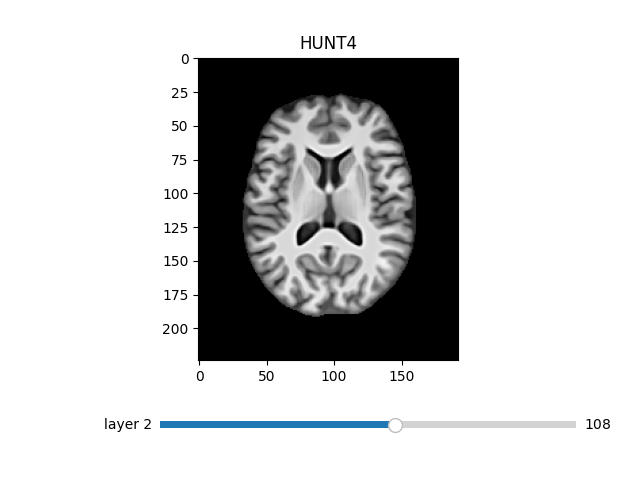

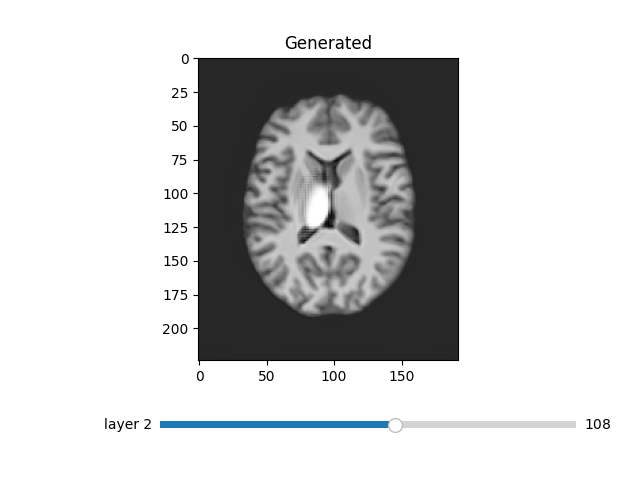

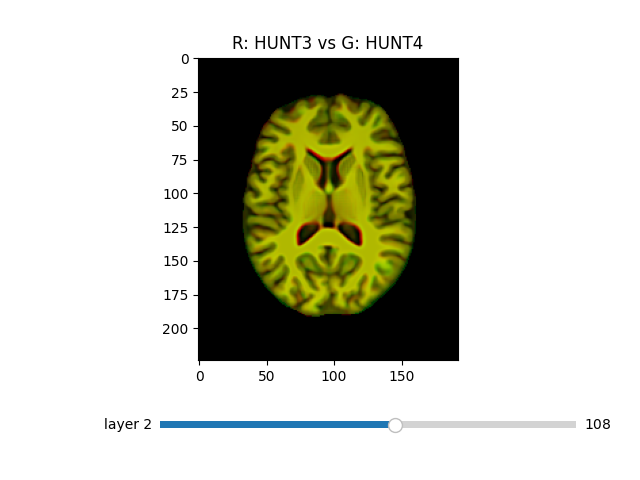

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


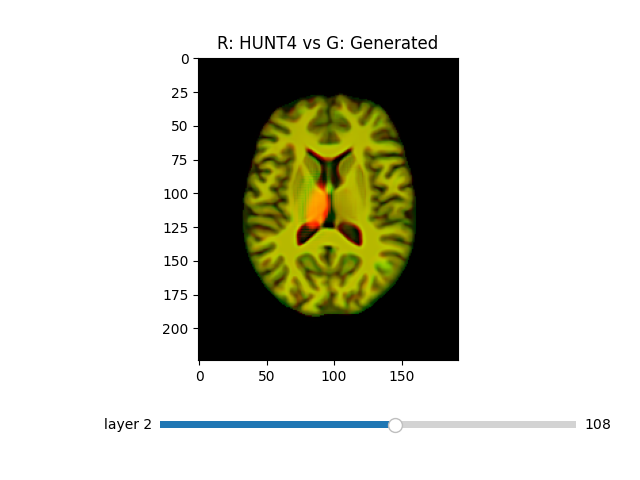

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


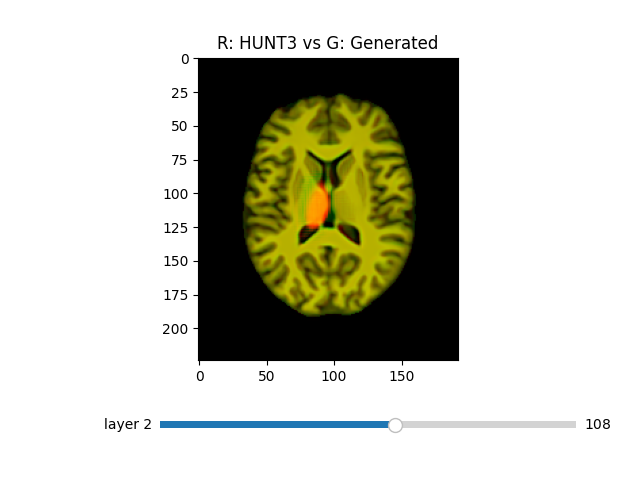

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i

In [4]:
%matplotlib widget
# %matplotlib tk
# %matplotlib inline

current_plane = 108

def shows_rgb_img(img_fixed, img_reg, name=""):
    img_rgb = np.stack((img_reg, img_fixed, np.zeros_like(img_fixed)), axis=3)
    fc.imgshow_3D(name, img_rgb, current_plane=current_plane, transpose=True, flip_ax=0)


for x_batch, y_batch in [data_train[302]]:
    # data = data_train[i]
    img_generated = G(x_batch)

    # fc.imgshow_3D(f"HUNT3", data[0][0,0], current_plane=current_plane)
    # fc.imgshow_3D(f"HUNT4", data[1][0,0], current_plane=current_plane)
    # fc.imgshow_3D(f"Generaed", img_generated[0,0], current_plane=current_plane)

    # rgb_image = np.stack((data[0][0,0], data[1][0,0], img_generated[0,0]), axis=3)
    # HUNT4_gen = np.stack((y_batch[0,0], img_generated[0,0], np.zeros_like(img_generated[0,0])), axis=3)
    # HUNT3_gen = np.stack((x_batch[0,0], img_generated[0,0], np.zeros_like(img_generated[0,0])), axis=3)

    img_hunt3 = x_batch[0,0]
    img_hunt4 = y_batch[0,0]
    img_gen = img_generated[0,0]
    img_gen = img_gen / np.max(img_gen)

    fc.imgshow_3D(f"HUNT4", img_hunt4, current_plane=current_plane)
    fc.imgshow_3D(f"Generated", img_gen, current_plane=current_plane)

    shows_rgb_img(img_hunt4, img_hunt3, "R: HUNT3 vs G: HUNT4")
    shows_rgb_img(img_hunt4, img_gen, "R: HUNT4 vs G: Generated")
    shows_rgb_img(img_hunt3, img_gen, "R: HUNT3 vs G: Generated")
